In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Missing Values: ")
print(df.isnull().sum())

print("Duplicate Values: ")
print(df.duplicated().sum())

Missing Values: 
label      0
message    0
dtype: int64
Duplicate Values: 
403


In [4]:
#Drop Duplicate Values

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Dataset shape after cleaning: ", df.shape)

print("Remaining Duplicates: ", df.duplicated().sum())

print("Missing Values: ", df.isnull().sum())

Dataset shape after cleaning:  (5169, 2)
Remaining Duplicates:  0
Missing Values:  label      0
message    0
dtype: int64


In [5]:
#Drop Duplicate Values

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Dataset shape after cleaning: ", df.shape)

print("Remaining Duplicates: ", df.duplicated().sum())

print("Missing Values: ", df.isnull().sum())

Dataset shape after cleaning:  (5169, 2)
Remaining Duplicates:  0
Missing Values:  label      0
message    0
dtype: int64


In [6]:
print(df['label'].value_counts())

print("\nPercentage Distribution: ")
print(df['label'].value_counts(normalize=True) * 100)

label
ham     4516
spam     653
Name: count, dtype: int64

Percentage Distribution: 
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


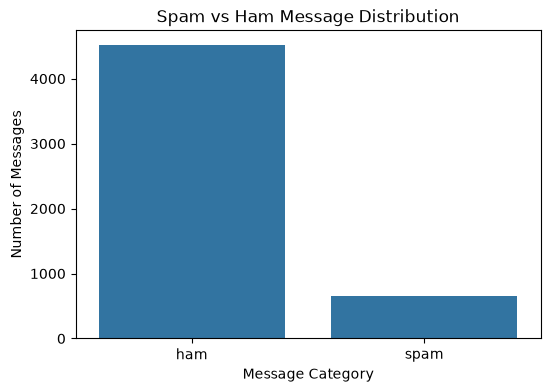

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='label')

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [8]:
df['message_length'] = df['message'].apply(len)

print(df.groupby('label')['message_length'].describe())

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4516.0   70.905890  56.715046   2.0   34.0   53.0   91.0  910.0
spam    653.0  137.704441  29.821348  13.0  132.0  148.0  157.0  223.0


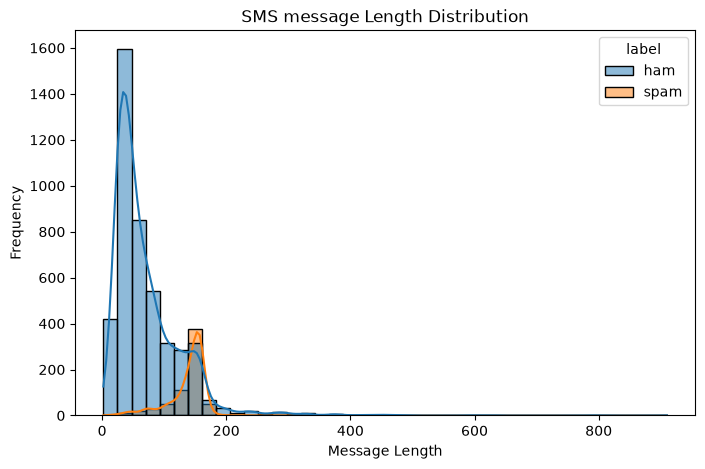

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins = 40,
    kde = True
)

plt.title("SMS message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")

plt.show()

In [10]:
df.to_csv("../dataset/cleaned_sms.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
